# Question 2 — **(a)**, **(b)**, and **(c)**

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAW / "diabetes.csv")
print("Dataset shape:", df.shape)
print("Missing values by column:")
display(df.isna().sum())
display(df.head())

import matplotlib.pyplot as plt
SEED = 42
print("Population shape:", df.shape)

Dataset shape: (768, 9)
Missing values by column:


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Population shape: (768, 9)


## (a) Set a seed (to ensure work reproducibility) and take a random sample of 25 observations and find the mean Glucose and highest Glucose values of this sample and compare these statistics with the population statistics of the same variable. You should use charts for this comparison. 

,Statistic,Sample (n=25),Population (N=768)
0,Mean Glucose,116.64,120.89
1,Maximum Glucose,183.00,199.00


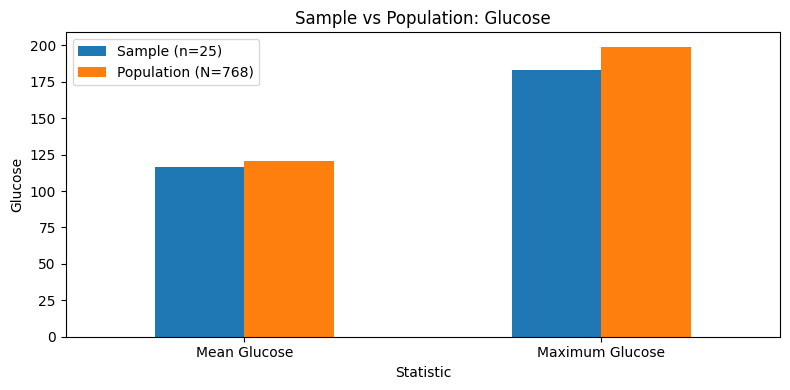

Mean Glucose: sample differs from population by -4.25 units.
Maximum Glucose: sample differs from population by -16.00 units.


In [9]:
sample_25 = df.sample(n=25, random_state=SEED, replace=False)
glucose_stats = pd.DataFrame({
    "Statistic": ["Mean Glucose", "Maximum Glucose"],
    "Sample (n=25)": [sample_25["Glucose"].mean(), sample_25["Glucose"].max()],
    "Population (N=768)": [df["Glucose"].mean(), df["Glucose"].max()]
})
display(glucose_stats.round(2))
ax = glucose_stats.set_index("Statistic").plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("Glucose")
ax.set_title("Sample vs Population: Glucose")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

for _, row in glucose_stats.iterrows():
    diff = row["Sample (n=25)"] - row["Population (N=768)"]
    print(f"{row['Statistic']}: sample differs from population by {diff:+.2f} units.")

## (b) Find the 98th percentile of BMI of your sample and the population and compare the results using charts.

,Group,BMI 98th Percentile
0,Sample (n=25),40.25
1,Population (N=768),47.53


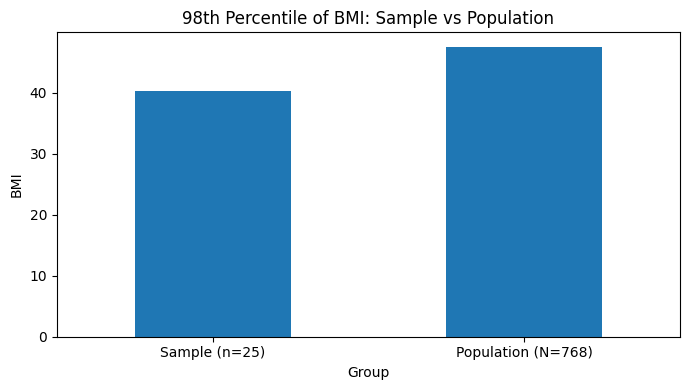

Difference (sample − population): -7.28 BMI units.


In [10]:
bmi_stats = pd.DataFrame({
    "Group": ["Sample (n=25)", "Population (N=768)"],
    "BMI 98th Percentile": [np.percentile(sample_25["BMI"], 98), np.percentile(df["BMI"], 98)]
})
display(bmi_stats.round(2))
ax = bmi_stats.plot(x="Group", y="BMI 98th Percentile", kind="bar", legend=False, figsize=(7, 4), rot=0)
ax.set_ylabel("BMI")
ax.set_title("98th Percentile of BMI: Sample vs Population")
plt.tight_layout()
plt.show()
print(f"Difference (sample − population): {bmi_stats.iloc[0,1] - bmi_stats.iloc[1,1]:+.2f} BMI units.")

## (c) Using bootstrap (replace= True), create 500 samples (of 150 observation each) from the population and find the average mean, standard deviation and percentile for BloodPressure and compare this with these statistics from the population for the same variable. Again, you should create charts for this comparison. Report on your findings

In [11]:
rng = np.random.default_rng(SEED)
bp = df["BloodPressure"].to_numpy()
N_BOOT = 500
BOOT_SIZE = 150
bootstrap_stats = []
for i in range(N_BOOT):
    boot = rng.choice(bp, size=BOOT_SIZE, replace=True)
    bootstrap_stats.append({
        "Mean": np.mean(boot),
        "Std Dev": np.std(boot, ddof=1),
        "98th Percentile": np.percentile(boot, 98)
    })
bootstrap_stats = pd.DataFrame(bootstrap_stats)
population_stats = pd.Series({
    "Mean": df["BloodPressure"].mean(),
    "Std Dev": df["BloodPressure"].std(ddof=0),
    "98th Percentile": np.percentile(bp, 98)
})
comparison = pd.DataFrame({
    "Average of 500 Bootstrap Statistics": bootstrap_stats.mean(),
    "Population Statistic": population_stats
})
comparison["Difference"] = comparison.iloc[:,0] - comparison.iloc[:,1]
display(comparison.round(2))

,Average of 500 Bootstrap Statistics,Population Statistic,Difference
Mean,69.14,69.11,0.03
Std Dev,19.05,19.34,-0.30
98th Percentile,97.89,99.32,-1.43


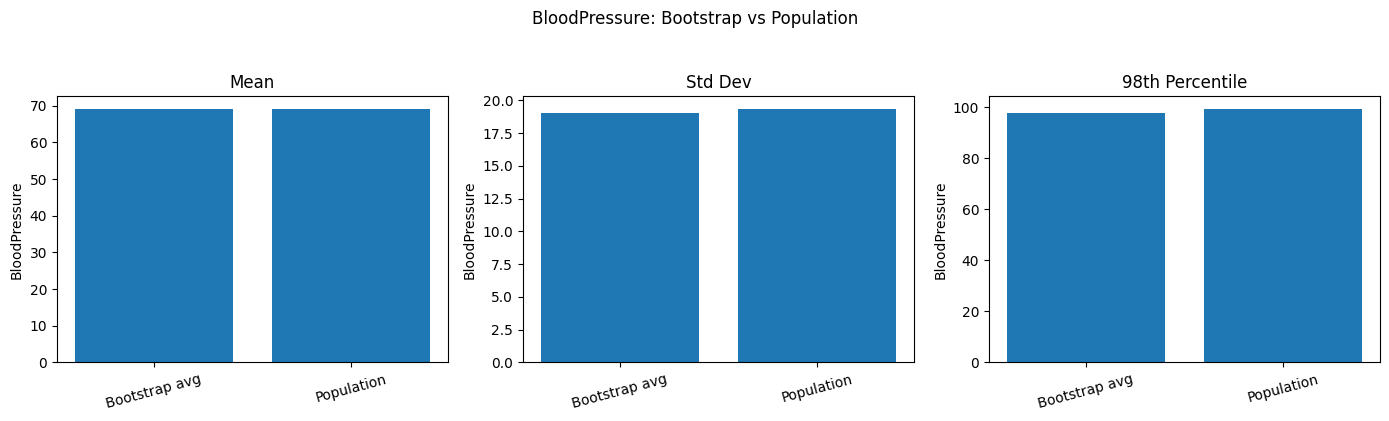

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, statistic in zip(axes, comparison.index):
    vals = comparison.loc[statistic, ["Average of 500 Bootstrap Statistics", "Population Statistic"]]
    ax.bar(["Bootstrap avg", "Population"], vals.to_numpy())
    ax.set_title(statistic)
    ax.set_ylabel("BloodPressure")
    ax.tick_params(axis="x", labelrotation=15)
plt.suptitle("BloodPressure: Bootstrap vs Population", y=1.04)
plt.tight_layout()
plt.show()

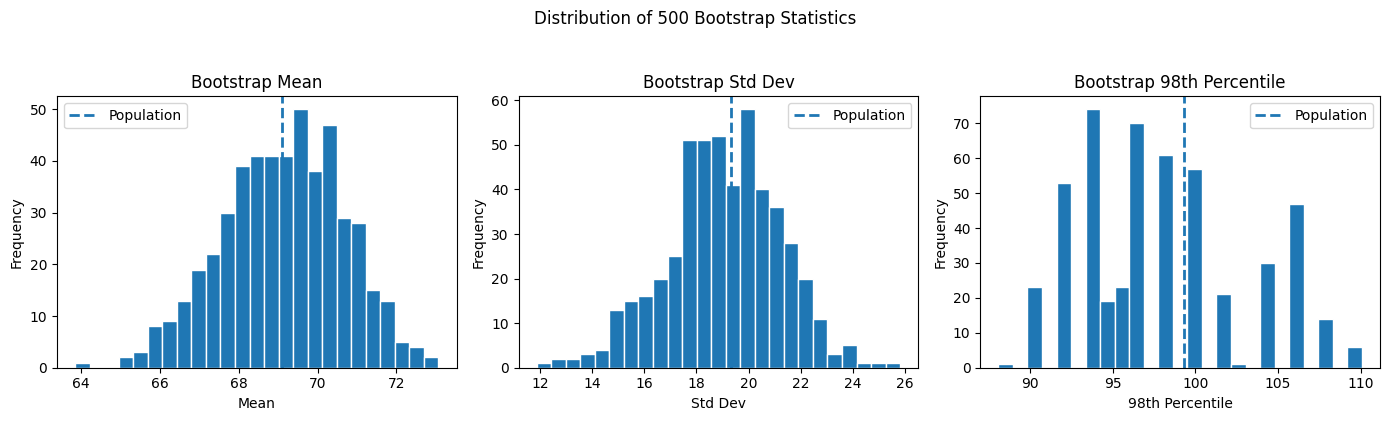

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, statistic in zip(axes, bootstrap_stats.columns):
    ax.hist(bootstrap_stats[statistic], bins=25, edgecolor="white")
    ax.axvline(population_stats[statistic], linestyle="--", linewidth=2, label="Population")
    ax.set_title(f"Bootstrap {statistic}")
    ax.set_xlabel(statistic)
    ax.set_ylabel("Frequency")
    ax.legend()
plt.suptitle("Distribution of 500 Bootstrap Statistics", y=1.04)
plt.tight_layout()
plt.show()

In [14]:
for statistic in comparison.index:
    boot_avg = comparison.loc[statistic, "Average of 500 Bootstrap Statistics"]
    pop_val = comparison.loc[statistic, "Population Statistic"]
    print(f"- {statistic}: bootstrap average = {boot_avg:.2f}; population = {pop_val:.2f}; difference = {boot_avg-pop_val:+.2f}.")

- Mean: bootstrap average = 69.14; population = 69.11; difference = +0.03.
- Std Dev: bootstrap average = 19.05; population = 19.34; difference = -0.30.
- 98th Percentile: bootstrap average = 97.89; population = 99.32; difference = -1.43.


### (c) Findings

500 bootstrap samples were generated, each containing 150 observations selected with replacement.

| Statistic | Bootstrap Average | Population | Difference |
|---|---:|---:|---:|
| Mean | 69.14 | 69.11 | +0.03 |
| Standard Deviation | 19.05 | 19.34 | -0.30 |
| 98th Percentile | 97.89 | 99.32 | -1.43 |


- The bootstrap mean (69.14) is very close to the population mean (69.11), with a difference of only 0.03.
- The bootstrap standard deviation (19.05) is slightly lower than the population standard deviation (19.34).
- The bootstrap 98th percentile (97.89) is also slightly lower than the population value (99.32).
- Since sampling is done with replacement, some observations appear multiple times within the same bootstrap sample.

The bootstrap results are close to the population statistics, especially for the mean BloodPressure. The standard deviation and 98th percentile show slightly larger differences, indicating that these statistics are more sensitive to sampling variation.